In [1]:
import copy
import os
import math
import time

import numpy as np
import torch
from torch import nn, Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from typing import Literal, Tuple, Callable, NamedTuple
import pandas as pd

SEED = 2021
np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [2]:
class LTSFLinearParams(NamedTuple):
    num_channels: int  # Number of individual time series in multivariate series.
    lookback_size: int=512
    prediction_size: int=96

    def __str__(self):
        return f"Lin(M={self.num_channels}, L={self.lookback_size}," \
            + f" T={self.prediction_size}"


class LTSFLinearPerChannel(nn.Module):
    """Linear layer per channel."""
    def __init__(self, args: LTSFLinearParams):
        super().__init__()
        self.args = args
        self.linears = nn.ModuleList([
            nn.Linear(args.lookback_size, args.prediction_size) for i in range(args.num_channels)
        ])

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, prediction_size)

        Each channel is one time series from the multivariate series.
        """
        outputs = [self.linears[i](X[:, i, :]) for i in range(X.shape[1])]
        return torch.stack(outputs, dim=1)


class LTSFLinear(nn.Module):
    """One shared linear layer for all channels."""
    def __init__(self, args: LTSFLinearParams):
        super().__init__()
        self.args = args
        self.linear = nn.Linear(args.lookback_size, args.prediction_size)

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, prediction_size)

        Each channel is one time series from the multivariate series.
        """
        return self.linear(X)


In [3]:
def load_time_series_data(
    file_path: str,
    delimiter: str = ",",
    missing_values = "***",
    filling_values = 0,
) -> np.ndarray:
    """
    Load raw multivariate time-series data into a 2D float tensor of shape (T, num_channels).

    The file is expected to be a text file with no header row or index (time) column. I.e., it
    should directly be raw data rows. Each row must record a timestamp, and each column a channel
    of the multivariate series.
    """
    arr = np.genfromtxt(file_path,
                        delimiter=delimiter,
                        missing_values=missing_values,
                        filling_values=filling_values)
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D tensor of shape (T, num_channels), got shape {arr.shape}")

    return arr


def to_data_loader(data: Dataset, batch_size: int, collate_fn=None, shuffle=False, seed=SEED) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)

    return DataLoader(
        data,
        batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        generator=g)


def split_time_series_data(
    raw_data: np.ndarray,
    lookback_size: int,
    prediction_size: int,
    split_ratios: Tuple[float, float, float] = (0.7, 0.1, 0.2),
    batch_size: int = 24,
    dtype: torch.dtype = torch.float32,
) -> Tuple[
    DataLoader[TensorDataset],
    DataLoader[TensorDataset],
    DataLoader[TensorDataset],
    StandardScaler
]:
    """
    Construct a PyTorch TensorDataset containing (X, Y) sliding-window pairs. Each window pair
    logically consists of X_i = [...lookback_size...] historic time steps used to predict
    Y_i = [...prediction_size...] events into the future, for each channel.

    In other words,
        X[i] = data[i : i + lookback_size]^T    shape: (num_channels, lookback_size)
        Y[i] = data[i + lookback_size : i + lookback_size + prediction_size]^T
                                                shape: (num_channels, prediction_size)
    Returns:
       train/val/test: `DataLoader`s, containing `TensorDataset`s that have:
                tensors[0] (X): shape (N, num_channels, lookback_size)
                tensors[1] (Y): shape (N, num_channels, prediction_size)
            where N is the number of valid sliding windows. Data is standardized.

        scaler: the `StandardScaler` used to standardize the data, in order to
            reverse the process for plotting in the original scale of the data.
    """
    scaler = StandardScaler()
    has_fit = False
    def lookback_and_prediction_windows(split: np.ndarray) -> Dataset:
        nonlocal scaler, has_fit
        split = scaler.transform(split) if has_fit else scaler.fit_transform(split)
        has_fit = True

        # Stride of 1: heavily overlap samples.
        # Unfolding yields the shape (N_samples, channels, window_size)
        tensor = torch.from_numpy(split).to(dtype=dtype)
        X = tensor.unfold(dimension=0, size=lookback_size, step=1)
        Y = tensor[lookback_size:].unfold(dimension=0, size=prediction_size, step=1)

        num_samples = min(X.shape[0], Y.shape[0])
        dataset = TensorDataset(X[:num_samples], Y[:num_samples])

        return dataset

    num_timesteps, _ = raw_data.shape

    train_ratio, val_ratio, _ = split_ratios
    train_size = int(num_timesteps * train_ratio)
    val_size = int(num_timesteps * val_ratio)
    test_size = num_timesteps - train_size - val_size

    # Pull lookback windows in val/test from the split before it (predicted values
    # in val/test are never seen from another split).
    # This matches the offical code's implementation.
    train_dataset, val_dataset, test_dataset = map(lookback_and_prediction_windows, [
        raw_data[:train_size],
        raw_data[train_size - lookback_size:train_size + val_size],
        raw_data[num_timesteps - test_size - lookback_size:],
    ])

    return to_data_loader(train_dataset, batch_size, shuffle=True), \
            to_data_loader(val_dataset, batch_size), \
            to_data_loader(test_dataset, batch_size), \
            scaler

In [4]:
def check_cuda_memory():
    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)
    peak = torch.cuda.max_memory_allocated() / (1024 ** 3)

    print(f"Allocated: {allocated:.2f} GB | Reserved: {reserved:.2f} GB | Peak: {peak:.2f} GB")


def train_epoch(
        model: nn.Module,
        train_loader: DataLoader,
        loss_fn,
        optimizer) -> float:
    model.train()
    total_loss = 0.0   # sum of per-example losses
    total_examples = 0
    for batch in train_loader:
        X, y = batch[0], batch[1]  # Work with TensorDataset or RandomizedChannelDataset

        # Typical training workflow: Dataset/loader are on the CPU.
        # Just load one batch to the GPU.
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss = loss_fn(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # scheduler.step()

        # loss_fn returns the mean over the batch, so multiply back out by the
        # batch size to accumulate an exact, example-weighted average (the final
        # batch is smaller, so a plain mean of batch means would be biased).
        total_loss += loss.item() * y.numel()
        total_examples += y.numel()

    return total_loss / total_examples


def evaluate(
        model: nn.Module,
        data_loader: DataLoader[TensorDataset],
        loss_fn: nn.Module,
        channel_chunk_size=96) -> float:
    # channel_chunk_size: Take small windows of channels to avoid running out of memory
    # on the GPU. This works with a validation/test dataloader that does not do any
    # windowing of channels (a plain TensorDataset), or one that is already windowing
    # RandomizedChannelDataset (in which case splitting here may only yield one item).
    model.eval()
    total_loss = 0.0
    count = 0
    with torch.no_grad():
        for batch in data_loader:  # (batch_size, channels, time_window_size)
            X, y = batch[0], batch[1]  # Work with TensorDataset or RandomizedChannelDataset

            for Xc, yc in zip(X.split(channel_chunk_size, dim=1), y.split(channel_chunk_size, dim=1)):
                Xc, yc = Xc.to(device), yc.to(device)
                total_loss += loss_fn(model(Xc), yc).item() * yc.numel()
                count += yc.numel()
    return total_loss / count


def train_early_stopping(
        model: nn.Module,
        train_loader,
        valid_loader,
        loss_fn,
        optimizer,
        epochs,
        verbosity: Literal[0]|Literal[1]|Literal[2] = 0
) -> tuple[list[float], list[float]]:
    best_val_loss = float('inf')
    patience_counter = 0
    patience = 10          # number of epochs to wait for an improvement
    best_state = None

    train_losses, valid_losses = [], []
    for epoch in range(epochs):
        start = time.time()
        train_loss = train_epoch(model, train_loader, loss_fn, optimizer)
        if verbosity > 1:
            print(f'  train time {time.time() - start:.0f}s')

        eval_start = time.time()
        val_loss = evaluate(model, valid_loader, loss_fn)
        if verbosity > 1:
            print(f'  eval time {time.time() - eval_start:.0f}s')

        if verbosity > 0:
            print(f'epoch {epoch + 1:2d}  train loss {train_loss:.3f}  '
                f'val loss {val_loss:.3f}  '
                f'({time.time() - start:.0f}s)')
            if epoch % 5 == 0 and verbosity > 1:
                check_cuda_memory()

        train_losses.append(train_loss)
        valid_losses.append(val_loss)

        if val_loss < best_val_loss:
            # still improving: remember this model as the best so far
            best_val_loss = val_loss
            patience_counter = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            # not better than our current best.  keep training for a few more epochs
            # to give it a chance to improve (that is what `patience` controls)
            patience_counter += 1
            if patience_counter >= patience:
                break

    # Restore the best weights before evaluating. Large LRs will fail
    # to produce a validation loss < best_val_loss. Don't restore to
    # anything in this case.
    if best_state:
        model.load_state_dict(best_state)

    return train_losses, valid_losses


def plot_loss(
    train_losses: list[float],
    val_losses: list[float],
    title: str = ""
):
    epochs_axis = range(1, len(train_losses) + 1)
    _, ax_loss = plt.subplots(figsize=(4, 2.4))

    l1 = ax_loss.plot(epochs_axis, train_losses, label='training loss')
    l2 = ax_loss.plot(epochs_axis, val_losses, label='validation loss')
    ax_loss.set_xlabel('epoch')
    ax_loss.set_ylabel('loss')

    lines = l1 + l2
    ax_loss.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.3, 1), loc='upper left')
    plt.title(title)


class ExperimentRunner:
    """
    A class that facilitates experimenting with different model configurations.
    Each added experiment gets `n` models trained with a different random seed (`n = 5`).
    Averaged results are returned in a dataframe after evaluating the models against
    the validation set. Plotting some/all of the experiments is also possible.
    """
    REPORT_COLUMNS = ["Classifier", "Loss (val)", "Epochs", "Param count"]

    # Results used in plots, saved in case we want to recall results from this
    # runner without re-running all experiments.
    class ExpResults(NamedTuple):
        params: NamedTuple
        model: nn.Module
        train_losses: list[float]
        val_losses: list[float]

    def __init__(self, model_constr: Callable[[NamedTuple], nn.Module]):
        self.model_constr = model_constr

        # Subclass used for hyperparams. E.g., TDNNHyperParams. Model must be
        # constructable by running model_constr(experiment_params).
        self.experiments: list[NamedTuple] = []
        self.experiments_to_plot: set[str] = set()
        self.experiment_results: list[ExperimentRunner.ExpResults] = []

        self.epochs: int = -1
        self.lr: float = 0.0001
        self.train_loader = None
        self.val_loader = None

    def with_epochs(self, epochs: int) -> ExperimentRunner:
        self.epochs = epochs
        return self

    def with_lr(self, lr: float) -> ExperimentRunner:
        self.lr = lr
        return self

    def with_data(self, train_loader: DataLoader, val_loader: DataLoader) -> ExperimentRunner:
        self.train_loader = train_loader
        self.val_loader = val_loader
        return self

    def add_experiments(self, *params) -> ExperimentRunner:
        self.experiments.extend(params)
        return self

    def and_plot(self, *params) -> ExperimentRunner:
        """Plot a given set of hyper params. These must match planned experiments."""
        self.experiments_to_plot.update(map(str, params))
        return self

    def with_plots(self) -> ExperimentRunner:
        """Plot all experiments recorded thus far when this runner is executed."""
        self.experiments_to_plot.update(map(str, self.experiments))
        return self

    def get_results(self) -> list[ExperimentRunner.ExpResults]:
        return self.experiment_results.copy()

    def run(self, verbosity: Literal[0]|Literal[1]|Literal[2] = 0) -> pd.DataFrame:
        run_data = []
        for params in self.experiments:
            plot_name = None
            serialized_params = str(params)
            print(f"Running experiment: {params}")

            if serialized_params in self.experiments_to_plot:
                plot_name = serialized_params

            model = self.model_constr(params).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=self.lr)
            # scheduler = torch.optim.lr_scheduler.OneCycleLR(
            #     optimizer,
            #     pct_start=0.2,
            #     max_lr=self.lr,
            #     epochs=self.epochs,
            #     steps_per_epoch=len(self.train_loader))
            loss_fn = nn.MSELoss()

            train_losses, val_losses = train_early_stopping(
                model,
                self.train_loader,
                self.val_loader,
                loss_fn=loss_fn,
                optimizer=optimizer,
                epochs=self.epochs,
                verbosity=verbosity)
            self.experiment_results.append(ExperimentRunner.ExpResults(
                params=params,
                model=model.cpu(),
                train_losses=train_losses,
                val_losses=val_losses))
            if plot_name:
                plot_loss(
                    train_losses=train_losses,
                    val_losses=val_losses,
                    title=plot_name,
                )

            param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
            actual_epochs = len(train_losses)
            run_data.append([serialized_params, min(val_losses), actual_epochs, param_count])

        df = pd.DataFrame(
            run_data,
            columns=self.REPORT_COLUMNS
        )
        return df.round(4).astype(object).fillna("Diverged")


In [5]:
# NOTE: This only works with TensorDataset.
# `show_prediction_from_randomized_channel_set` works with RandomizedChannelDataset.
def show_random_prediction(
        models: list[nn.Module],
        loader: DataLoader[TensorDataset],
        scaler: StandardScaler,
        channel_labels: list[str] = []):
    # Grab the first sample from the first batch, channel 0.
    # When using the val loader, this sample starts on line 11,769 of
    # the full dataset.
    # The scaler expects items in the shape (time, num_channels).
    random_time = np.random.randint(0, len(loader.dataset))
    X, Y = loader.dataset[random_time]  # (channels, lookback/pred_size)
    channel = np.random.randint(0, len(X))
    sample = Tensor(scaler.inverse_transform(X.T).T[channel])
    truth = Tensor(scaler.inverse_transform(Y.T).T[channel])

    _, ax = plt.subplots(figsize=(10, 4))

    prediction_xticks = np.arange(len(sample), len(sample) + len(truth))
    l1 = ax.plot(sample, label='lookback window')
    l2 = ax.plot(prediction_xticks, truth,
                label='true future series')

    lines = l1 + l2
    for model in models:
        with torch.no_grad():
            single_sample_batch = X.unsqueeze(0)
            model = model.to(device)
            model.eval()
            all_preds = model(single_sample_batch.to(device)).cpu()
            preds = scaler.inverse_transform(all_preds[0].T).T[channel]

        # print("lookback window, future truth, future prediction",
        #     sample.shape, truth.shape, preds.shape)

        line = ax.plot(prediction_xticks, preds,
                    label='predicted future series')
        lines += line

    if channel_labels:
        plt.title(channel_labels[channel])
    ax.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.05, 1), loc='upper left');


In [6]:
CHANNEL_LABELS = ["Temp", "Relative Humidity", "DewPt", "Wind", "WindDir", "Gust", "GustDir", "Pressure", "Solar", "Prec"]
TIME_SERIES_CHANNELS = ["Temp", "Relative Humidity", "DewPt", "Wind", "Pressure", "Solar"]
ci = { c: i for i, c in enumerate(CHANNEL_LABELS) }
selected_channels = list(map(lambda c: ci[c], TIME_SERIES_CHANNELS))

## `LTSFLinear`, Small weather data

In [32]:
sm_weather_data = load_time_series_data("./data/csu_weather_2020.csv", delimiter=",")[:, selected_channels]

weather_train_loader, weather_val_loader, weather_test_loader, weather_scaler = split_time_series_data(
    sm_weather_data,
    lookback_size=336,
    prediction_size=96,
    batch_size=32,
    split_ratios=(0.6, 0.2, 0.2))

train_batch_X, train_batch_Y = next(iter(weather_train_loader))
print("All data shape:        ", sm_weather_data.shape)
print("training batch_X shape:", train_batch_X.shape)
print("training batch_Y shape:", train_batch_Y.shape)
print("num batches:           ", len(weather_train_loader))
print("total training samples:", len(weather_train_loader.dataset))

val_batch_X, val_batch_Y = next(iter(weather_val_loader))
print("\nval batch_X shape:     ", val_batch_X.shape)
print("val batch_Y shape:     ", val_batch_Y.shape)
print("num batches:           ", len(weather_val_loader))
print("total val samples:     ", len(weather_val_loader.dataset))

test_batch_X, test_batch_Y = next(iter(weather_test_loader))
print("\ntest batch_X shape:    ", test_batch_X.shape)
print("test batch_Y shape:    ", test_batch_Y.shape)
print("num batches:           ", len(weather_test_loader))
print("total test samples:    ", len(weather_test_loader.dataset))

All data shape:         (8760, 6)
training batch_X shape: torch.Size([32, 6, 336])
training batch_Y shape: torch.Size([32, 6, 96])
num batches:            151
total training samples: 4825

val batch_X shape:      torch.Size([32, 6, 336])
val batch_Y shape:      torch.Size([32, 6, 96])
num batches:            52
total val samples:      1657

test batch_X shape:     torch.Size([32, 6, 336])
test batch_Y shape:     torch.Size([32, 6, 96])
num batches:            52
total test samples:     1657


In [14]:
np.linalg.cond(sm_weather_data)

np.float64(198.75147255768042)

Running experiment: Lin(M=6, L=336, T=96
epoch  1  train loss 0.783  val loss 0.466  (0s)
epoch  2  train loss 0.577  val loss 0.419  (0s)
epoch  3  train loss 0.542  val loss 0.399  (0s)
epoch  4  train loss 0.526  val loss 0.391  (0s)
epoch  5  train loss 0.517  val loss 0.385  (0s)
epoch  6  train loss 0.511  val loss 0.382  (0s)
epoch  7  train loss 0.506  val loss 0.380  (0s)
epoch  8  train loss 0.502  val loss 0.377  (0s)
epoch  9  train loss 0.500  val loss 0.376  (0s)
epoch 10  train loss 0.497  val loss 0.374  (0s)
epoch 11  train loss 0.495  val loss 0.373  (0s)
epoch 12  train loss 0.494  val loss 0.373  (0s)
epoch 13  train loss 0.492  val loss 0.373  (0s)
epoch 14  train loss 0.491  val loss 0.370  (0s)
epoch 15  train loss 0.490  val loss 0.369  (0s)
epoch 16  train loss 0.489  val loss 0.369  (0s)
epoch 17  train loss 0.488  val loss 0.367  (0s)
epoch 18  train loss 0.487  val loss 0.367  (0s)
epoch 19  train loss 0.487  val loss 0.368  (0s)
epoch 20  train loss 0.486  

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=6, L=336, T=96",0.3602,73,32352


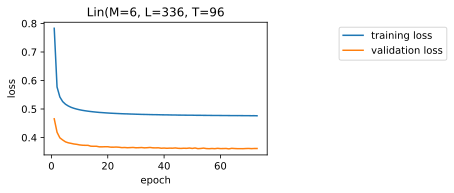

In [37]:
# 2020 weather data
# lr = 0.0001, no scheduler.
runner1_1 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(weather_train_loader, weather_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=sm_weather_data.shape[1],
                lookback_size=336,  # 42 patches
                prediction_size=96,
            )
        ).with_plots()
)

runner_results1_1 = runner1_1.run(verbosity=1)
runner_results1_1

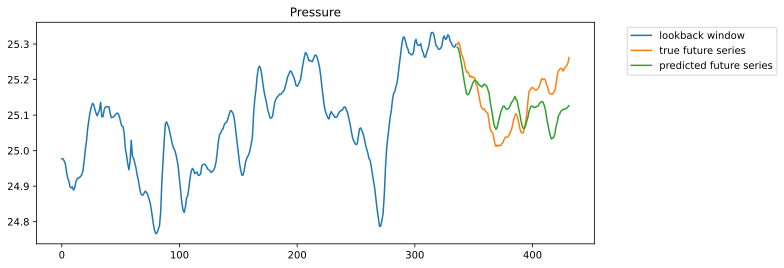

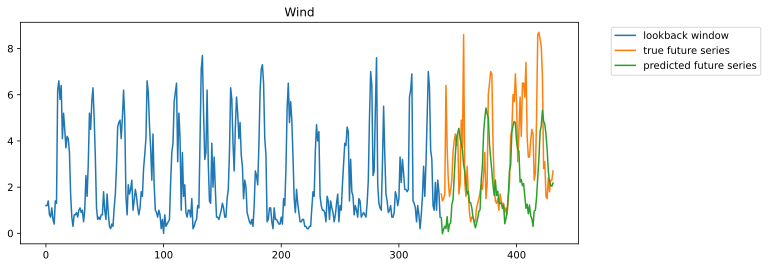

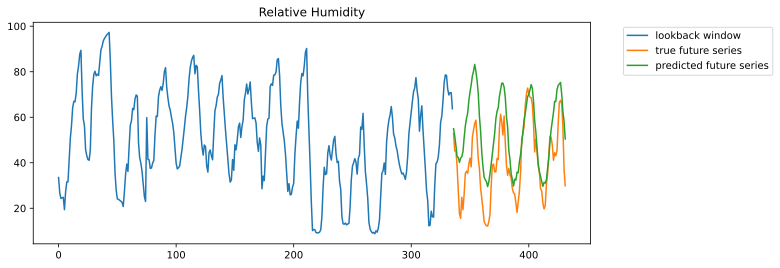

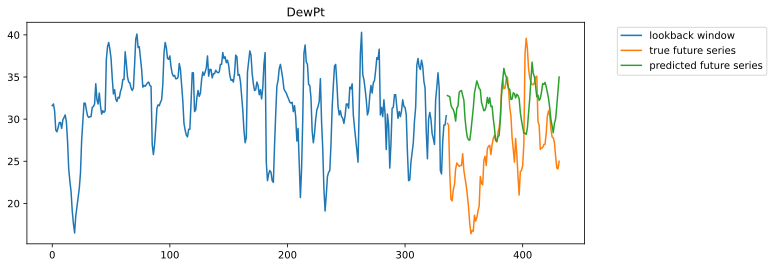

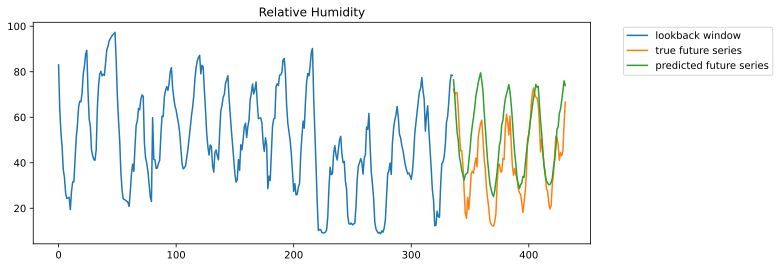

In [38]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner1.get_results())),
        weather_val_loader,
        weather_scaler,
        channel_labels=TIME_SERIES_CHANNELS)

In [24]:
weather_train_loader, weather_val_loader, weather_test_loader, weather_scaler = split_time_series_data(
    sm_weather_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=32,
    split_ratios=(0.6, 0.2, 0.2))

train_batch_X, train_batch_Y = next(iter(weather_train_loader))
print("All data shape:        ", sm_weather_data.shape)
print("training batch_X shape:", train_batch_X.shape)
print("training batch_Y shape:", train_batch_Y.shape)
print("num batches:           ", len(weather_train_loader))
print("total training samples:", len(weather_train_loader.dataset))

val_batch_X, val_batch_Y = next(iter(weather_val_loader))
print("\nval batch_X shape:     ", val_batch_X.shape)
print("val batch_Y shape:     ", val_batch_Y.shape)
print("num batches:           ", len(weather_val_loader))
print("total val samples:     ", len(weather_val_loader.dataset))

test_batch_X, test_batch_Y = next(iter(weather_test_loader))
print("\ntest batch_X shape:    ", test_batch_X.shape)
print("test batch_Y shape:    ", test_batch_Y.shape)
print("num batches:           ", len(weather_test_loader))
print("total test samples:    ", len(weather_test_loader.dataset))


All data shape:         (8760, 6)
training batch_X shape: torch.Size([32, 6, 512])
training batch_Y shape: torch.Size([32, 6, 96])
num batches:            146
total training samples: 4649

val batch_X shape:      torch.Size([32, 6, 512])
val batch_Y shape:      torch.Size([32, 6, 96])
num batches:            52
total val samples:      1657

test batch_X shape:     torch.Size([32, 6, 512])
test batch_Y shape:     torch.Size([32, 6, 96])
num batches:            52
total test samples:     1657


Running experiment: Lin(M=6, L=512, T=96
epoch  1  train loss 0.752  val loss 0.450  (0s)
epoch  2  train loss 0.553  val loss 0.415  (0s)
epoch  3  train loss 0.522  val loss 0.401  (0s)
epoch  4  train loss 0.508  val loss 0.396  (0s)
epoch  5  train loss 0.499  val loss 0.391  (0s)
epoch  6  train loss 0.493  val loss 0.389  (0s)
epoch  7  train loss 0.488  val loss 0.387  (0s)
epoch  8  train loss 0.484  val loss 0.384  (0s)
epoch  9  train loss 0.482  val loss 0.383  (0s)
epoch 10  train loss 0.479  val loss 0.381  (0s)
epoch 11  train loss 0.477  val loss 0.382  (0s)
epoch 12  train loss 0.476  val loss 0.380  (0s)
epoch 13  train loss 0.474  val loss 0.377  (0s)
epoch 14  train loss 0.473  val loss 0.377  (0s)
epoch 15  train loss 0.472  val loss 0.377  (0s)
epoch 16  train loss 0.471  val loss 0.378  (0s)
epoch 17  train loss 0.470  val loss 0.377  (0s)
epoch 18  train loss 0.469  val loss 0.376  (0s)
epoch 19  train loss 0.468  val loss 0.377  (0s)
epoch 20  train loss 0.468  

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=6, L=512, T=96",0.3694,46,49248


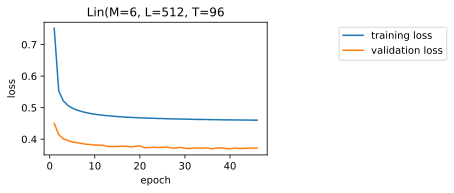

In [25]:
# lr = 0.0001, no scheduler.
runner1_2 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(weather_train_loader, weather_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=sm_weather_data.shape[1],
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

runner_results1_2 = runner1_2.run(verbosity=1)
runner_results1_2

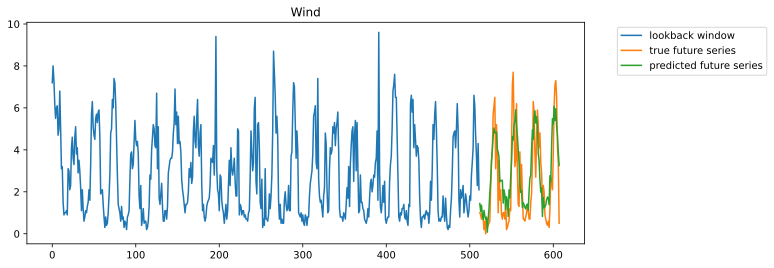

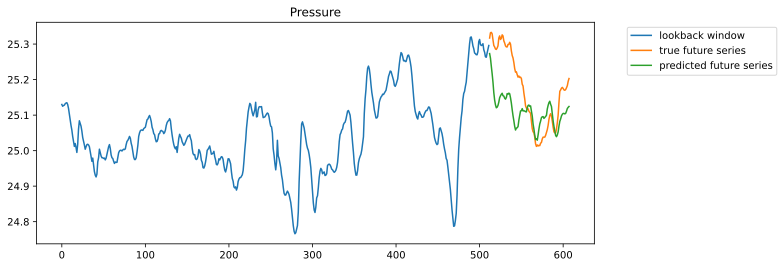

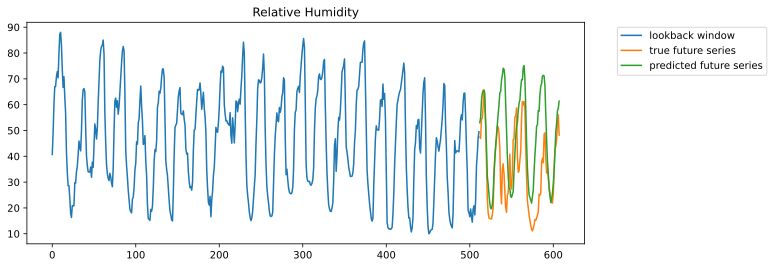

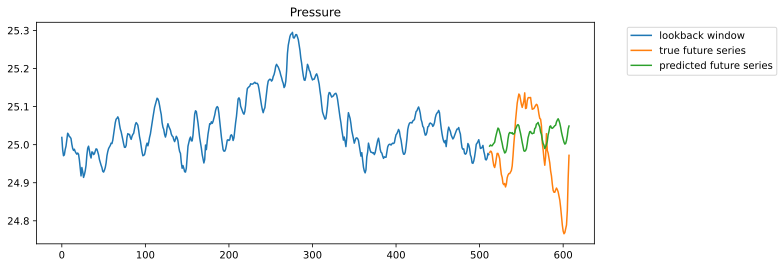

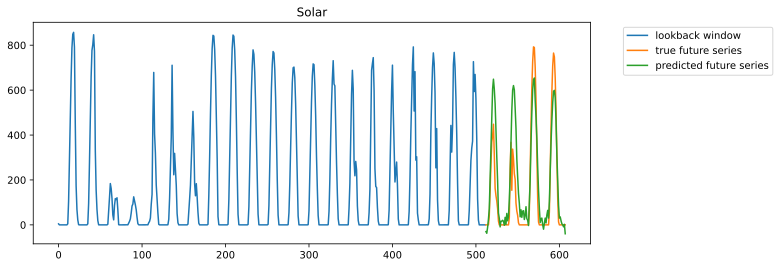

In [29]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner1_2.get_results())),
        weather_val_loader,
        weather_scaler,
        channel_labels=TIME_SERIES_CHANNELS)

In [85]:
all_weather_data = load_time_series_data("./data/csu_weather_2020_2025.csv", delimiter=",")[:, selected_channels]

weather_train_loader, weather_val_loader, weather_test_loader, weather_scaler = split_time_series_data(
    all_weather_data,
    lookback_size=336,
    prediction_size=96,
    batch_size=32,
    split_ratios=(0.6, 0.2, 0.2))

train_batch_X, train_batch_Y = next(iter(weather_train_loader))
print("All data shape:        ", all_weather_data.shape)
print("training batch_X shape:", train_batch_X.shape)
print("training batch_Y shape:", train_batch_Y.shape)
print("num batches:           ", len(weather_train_loader))
print("total training samples:", len(weather_train_loader.dataset))

val_batch_X, val_batch_Y = next(iter(weather_val_loader))
print("\nval batch_X shape:     ", val_batch_X.shape)
print("val batch_Y shape:     ", val_batch_Y.shape)
print("num batches:           ", len(weather_val_loader))
print("total val samples:     ", len(weather_val_loader.dataset))

test_batch_X, test_batch_Y = next(iter(weather_test_loader))
print("\ntest batch_X shape:    ", test_batch_X.shape)
print("test batch_Y shape:    ", test_batch_Y.shape)
print("num batches:           ", len(weather_test_loader))
print("total test samples:    ", len(weather_test_loader.dataset))

All data shape:         (52335, 6)
training batch_X shape: torch.Size([32, 6, 336])
training batch_Y shape: torch.Size([32, 6, 96])
num batches:            968
total training samples: 30970

val batch_X shape:      torch.Size([32, 6, 336])
val batch_Y shape:      torch.Size([32, 6, 96])
num batches:            325
total val samples:      10372

test batch_X shape:     torch.Size([32, 6, 336])
test batch_Y shape:     torch.Size([32, 6, 96])
num batches:            325
total test samples:     10372


Running experiment: Lin(M=6, L=336, T=96
epoch  1  train loss 0.614  val loss 0.397  (1s)
epoch  2  train loss 0.541  val loss 0.385  (1s)
epoch  3  train loss 0.527  val loss 0.380  (1s)
epoch  4  train loss 0.519  val loss 0.378  (1s)
epoch  5  train loss 0.514  val loss 0.376  (1s)
epoch  6  train loss 0.510  val loss 0.376  (1s)
epoch  7  train loss 0.507  val loss 0.374  (1s)
epoch  8  train loss 0.505  val loss 0.374  (1s)
epoch  9  train loss 0.504  val loss 0.373  (1s)
epoch 10  train loss 0.503  val loss 0.372  (1s)
epoch 11  train loss 0.502  val loss 0.372  (1s)
epoch 12  train loss 0.501  val loss 0.373  (1s)
epoch 13  train loss 0.501  val loss 0.372  (1s)
epoch 14  train loss 0.500  val loss 0.372  (1s)
epoch 15  train loss 0.500  val loss 0.372  (1s)
epoch 16  train loss 0.500  val loss 0.372  (1s)
epoch 17  train loss 0.500  val loss 0.373  (1s)
epoch 18  train loss 0.500  val loss 0.372  (1s)
epoch 19  train loss 0.500  val loss 0.372  (1s)
epoch 20  train loss 0.500  

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=6, L=336, T=96",0.3708,49,32352


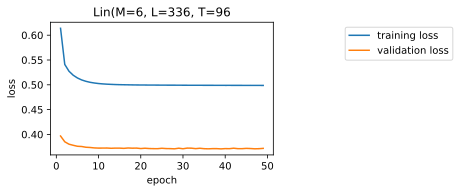

In [40]:
# ALL weather data.
# lr = 0.0001, no scheduler.
runner1_3 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(weather_train_loader, weather_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=sm_weather_data.shape[1],
                lookback_size=336,  # 42 patches
                prediction_size=96,
            )
        ).with_plots()
)

runner_results1_3 = runner1_3.run(verbosity=1)
runner_results1_3

In [86]:
weather_train_loader, weather_val_loader, weather_test_loader, weather_scaler = split_time_series_data(
    all_weather_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=32,
    split_ratios=(0.6, 0.2, 0.2))

Running experiment: Lin(M=6, L=512, T=96
epoch  1  train loss 0.603  val loss 0.388  (1s)
epoch  2  train loss 0.537  val loss 0.378  (1s)
epoch  3  train loss 0.523  val loss 0.374  (1s)
epoch  4  train loss 0.515  val loss 0.371  (1s)
epoch  5  train loss 0.510  val loss 0.371  (1s)
epoch  6  train loss 0.507  val loss 0.369  (1s)
epoch  7  train loss 0.504  val loss 0.368  (1s)
epoch  8  train loss 0.503  val loss 0.368  (1s)
epoch  9  train loss 0.501  val loss 0.367  (1s)
epoch 10  train loss 0.501  val loss 0.366  (1s)
epoch 11  train loss 0.500  val loss 0.367  (1s)
epoch 12  train loss 0.500  val loss 0.368  (1s)
epoch 13  train loss 0.499  val loss 0.367  (1s)
epoch 14  train loss 0.499  val loss 0.366  (1s)
epoch 15  train loss 0.499  val loss 0.367  (1s)
epoch 16  train loss 0.499  val loss 0.366  (1s)
epoch 17  train loss 0.499  val loss 0.366  (1s)
epoch 18  train loss 0.499  val loss 0.367  (1s)
epoch 19  train loss 0.498  val loss 0.366  (1s)
epoch 20  train loss 0.498  

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=6, L=512, T=96",0.3651,34,49248


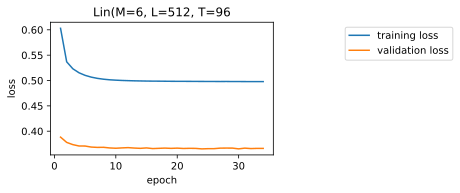

In [87]:
# ALL weather data. 512
# lr = 0.0001, no scheduler.
runner1_4 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(weather_train_loader, weather_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=sm_weather_data.shape[1],
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

runner_results1_4 = runner1_4.run(verbosity=1)
runner_results1_4

## `LTSFLinearPerChannel`

Loss of 0.4092 is higher than other models.

Running experiment: Lin(M=6, L=336, T=96
epoch  1  train loss 0.744  val loss 0.536  (0s)
epoch  2  train loss 0.555  val loss 0.486  (0s)
epoch  3  train loss 0.520  val loss 0.472  (0s)
epoch  4  train loss 0.503  val loss 0.453  (0s)
epoch  5  train loss 0.491  val loss 0.444  (0s)
epoch  6  train loss 0.483  val loss 0.445  (0s)
epoch  7  train loss 0.477  val loss 0.437  (0s)
epoch  8  train loss 0.472  val loss 0.434  (0s)
epoch  9  train loss 0.468  val loss 0.429  (0s)
epoch 10  train loss 0.465  val loss 0.432  (0s)
epoch 11  train loss 0.462  val loss 0.425  (0s)
epoch 12  train loss 0.460  val loss 0.425  (0s)
epoch 13  train loss 0.458  val loss 0.427  (0s)
epoch 14  train loss 0.456  val loss 0.425  (0s)
epoch 15  train loss 0.455  val loss 0.424  (0s)
epoch 16  train loss 0.453  val loss 0.418  (0s)
epoch 17  train loss 0.452  val loss 0.423  (0s)
epoch 18  train loss 0.451  val loss 0.424  (0s)
epoch 19  train loss 0.450  val loss 0.420  (0s)
epoch 20  train loss 0.449  

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=6, L=336, T=96",0.4092,51,194112


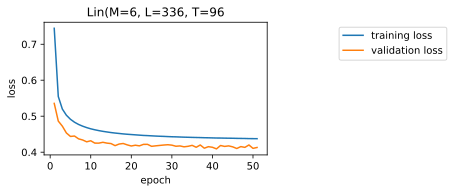

In [17]:
# lr = 0.0001, no scheduler.
runner2 = (
    ExperimentRunner(LTSFLinearPerChannel)
        .with_epochs(100)
        .with_data(weather_train_loader, weather_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=sm_weather_data.shape[1],
                lookback_size=336,  # 42 patches
                prediction_size=96,
            )
        ).with_plots()
)

runner_results2 = runner2.run(verbosity=1)
runner_results2

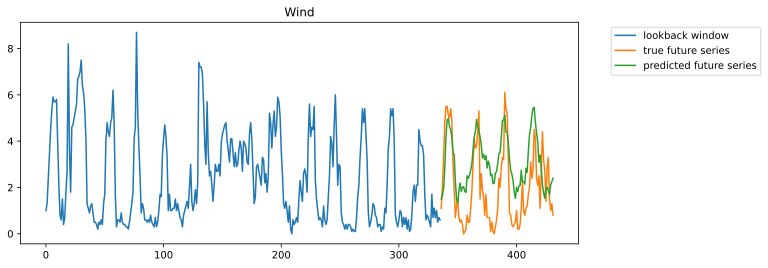

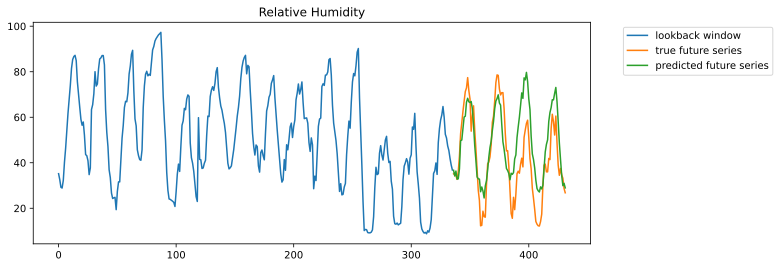

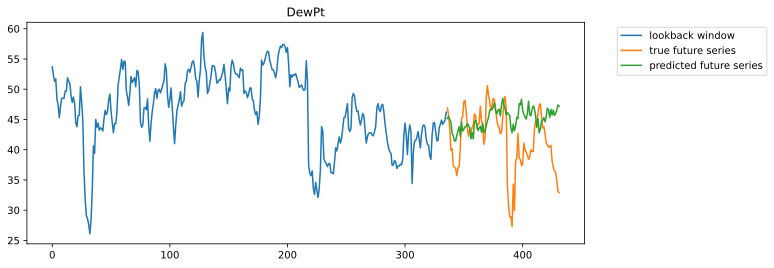

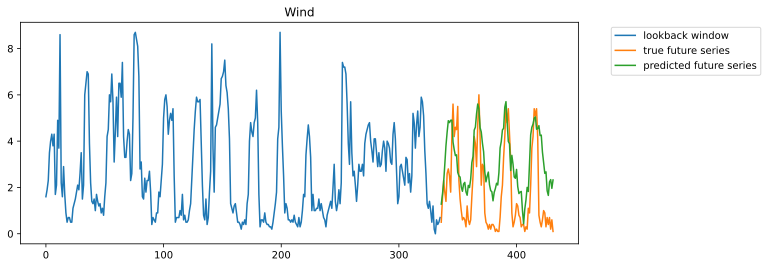

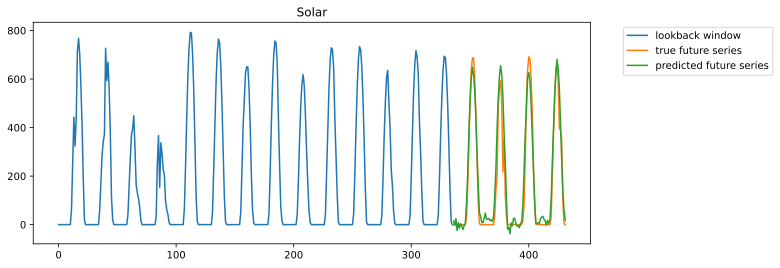

In [23]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner2.get_results())),
        weather_val_loader,
        weather_scaler,
        channel_labels=TIME_SERIES_CHANNELS)

Running experiment: Lin(M=6, L=512, T=96
epoch  1  train loss 0.598  val loss 0.386  (1s)
epoch  2  train loss 0.531  val loss 0.374  (1s)
epoch  3  train loss 0.516  val loss 0.369  (1s)
epoch  4  train loss 0.507  val loss 0.367  (1s)
epoch  5  train loss 0.501  val loss 0.365  (1s)
epoch  6  train loss 0.497  val loss 0.365  (1s)
epoch  7  train loss 0.493  val loss 0.363  (1s)
epoch  8  train loss 0.491  val loss 0.364  (1s)
epoch  9  train loss 0.489  val loss 0.362  (1s)
epoch 10  train loss 0.488  val loss 0.361  (1s)
epoch 11  train loss 0.487  val loss 0.360  (1s)
epoch 12  train loss 0.486  val loss 0.361  (1s)
epoch 13  train loss 0.485  val loss 0.360  (1s)
epoch 14  train loss 0.485  val loss 0.360  (1s)
epoch 15  train loss 0.484  val loss 0.360  (1s)
epoch 16  train loss 0.484  val loss 0.359  (1s)
epoch 17  train loss 0.484  val loss 0.359  (1s)
epoch 18  train loss 0.483  val loss 0.359  (1s)
epoch 19  train loss 0.483  val loss 0.359  (1s)
epoch 20  train loss 0.483  

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=6, L=512, T=96",0.3567,41,295488


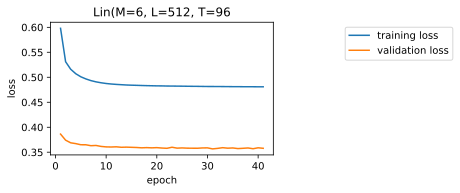

In [88]:
# lr = 0.0001, no scheduler.
runner2_2 = (
    ExperimentRunner(LTSFLinearPerChannel)
        .with_epochs(100)
        .with_data(weather_train_loader, weather_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=sm_weather_data.shape[1],
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

runner_results2_2 = runner2_2.run(verbosity=1)
runner_results2_2

## Larger prediction windows, $L= 336$, $T = 192$

**Traffic**

Results from `patch_tst.ipynb` with traffic data: 
- `PatchTST` val loss = 0.3377
- `LTSFLinear` val loss = 0.3453
- `LinearPatch` val loss = 0.3456

Takeaway: `PatchTST` has an edge on longer predictions.

In [44]:
weather_train_loader, weather_val_loader, weather_test_loader, weather_scaler = split_time_series_data(
    all_weather_data,
    lookback_size=336,
    prediction_size=192,
    batch_size=32,
    split_ratios=(0.6, 0.2, 0.2))

Running experiment: Lin(M=6, L=336, T=192
epoch  1  train loss 0.645  val loss 0.426  (1s)
epoch  2  train loss 0.574  val loss 0.417  (1s)
epoch  3  train loss 0.561  val loss 0.412  (1s)
epoch  4  train loss 0.553  val loss 0.410  (1s)
epoch  5  train loss 0.548  val loss 0.408  (1s)
epoch  6  train loss 0.545  val loss 0.407  (1s)
epoch  7  train loss 0.542  val loss 0.406  (1s)
epoch  8  train loss 0.540  val loss 0.406  (1s)
epoch  9  train loss 0.539  val loss 0.405  (1s)
epoch 10  train loss 0.537  val loss 0.406  (1s)
epoch 11  train loss 0.537  val loss 0.405  (1s)
epoch 12  train loss 0.536  val loss 0.404  (1s)
epoch 13  train loss 0.536  val loss 0.404  (1s)
epoch 14  train loss 0.536  val loss 0.405  (1s)
epoch 15  train loss 0.535  val loss 0.404  (1s)
epoch 16  train loss 0.535  val loss 0.404  (1s)
epoch 17  train loss 0.535  val loss 0.404  (1s)
epoch 18  train loss 0.535  val loss 0.403  (1s)
epoch 19  train loss 0.535  val loss 0.403  (1s)
epoch 20  train loss 0.535 

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=6, L=336, T=192",0.4032,34,64704


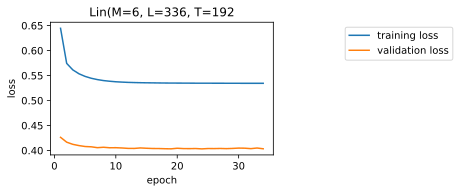

In [45]:
# lr = 0.0001, no scheduler.
runner3_1 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(weather_train_loader, weather_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=sm_weather_data.shape[1],
                lookback_size=336,  # 42 patches
                prediction_size=192,
            )
        ).with_plots()
)

runner_results3_1 = runner3_1.run(verbosity=1)
runner_results3_1

In [46]:
all_traffic_data = load_time_series_data("./data/traffic.txt", delimiter=",")
traffic_train_loader, traffic_val_loader, _, traffic_scaler = split_time_series_data(
    all_traffic_data,
    lookback_size=336,
    prediction_size=192,
    batch_size=64)

Running experiment: Lin(M=862, L=336, T=192
epoch  1  train loss 0.703  val loss 0.725  (6s)
epoch  2  train loss 0.457  val loss 0.566  (6s)
epoch  3  train loss 0.386  val loss 0.492  (6s)
epoch  4  train loss 0.348  val loss 0.451  (6s)
epoch  5  train loss 0.325  val loss 0.425  (6s)
epoch  6  train loss 0.309  val loss 0.408  (6s)
epoch  7  train loss 0.298  val loss 0.396  (6s)
epoch  8  train loss 0.289  val loss 0.386  (6s)
epoch  9  train loss 0.283  val loss 0.380  (6s)
epoch 10  train loss 0.278  val loss 0.374  (6s)
epoch 11  train loss 0.274  val loss 0.370  (6s)
epoch 12  train loss 0.271  val loss 0.366  (6s)
epoch 13  train loss 0.268  val loss 0.363  (6s)
epoch 14  train loss 0.266  val loss 0.361  (6s)
epoch 15  train loss 0.264  val loss 0.359  (6s)
epoch 16  train loss 0.262  val loss 0.357  (6s)
epoch 17  train loss 0.261  val loss 0.356  (6s)
epoch 18  train loss 0.260  val loss 0.354  (6s)
epoch 19  train loss 0.259  val loss 0.353  (6s)
epoch 20  train loss 0.25

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=862, L=336, T=192",0.3453,73,64704


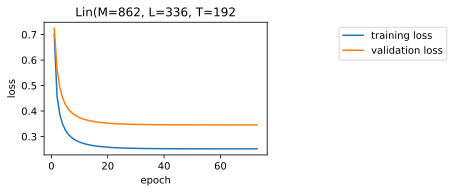

In [47]:
# Match settings in patch_tst
runner3_2 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(traffic_train_loader, traffic_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=all_traffic_data.shape[1],
                lookback_size=336,  # 42 patches
                prediction_size=192,
            )
        ).with_plots()
)

runner_results3_2 = runner3_2.run(verbosity=1)
runner_results3_2

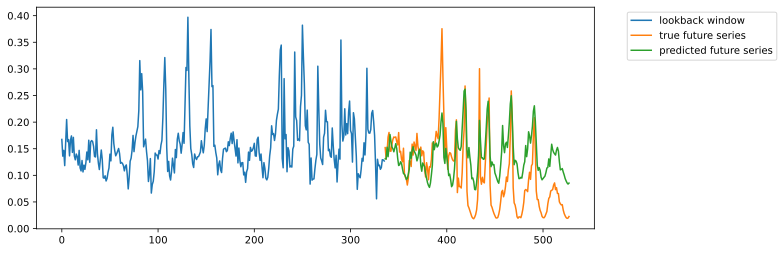

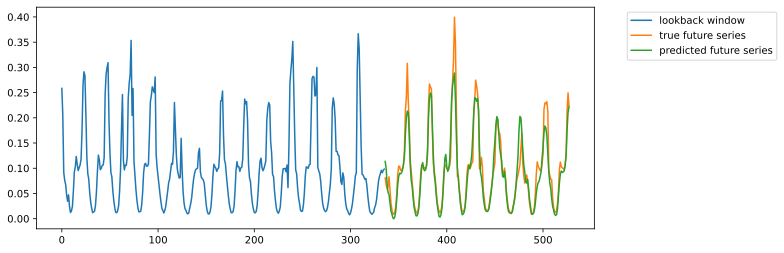

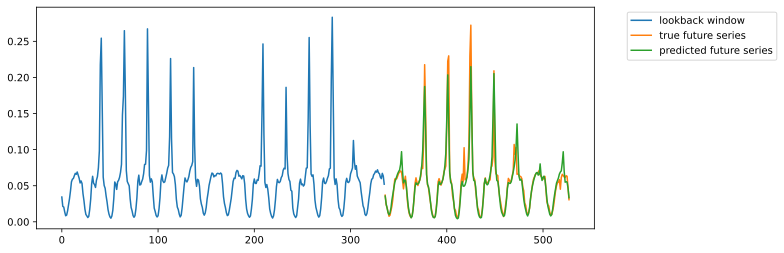

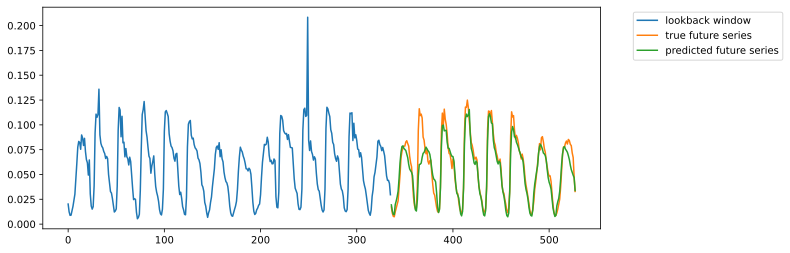

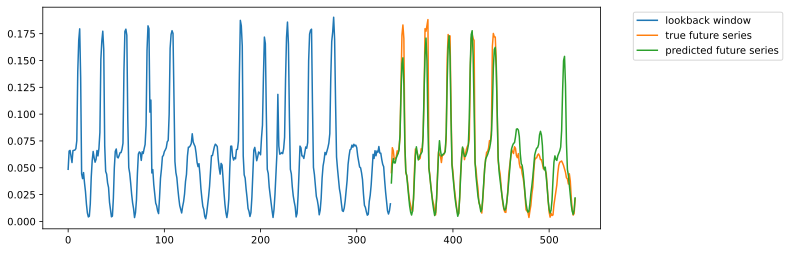

In [52]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner3_2.get_results())),
        traffic_val_loader,
        traffic_scaler)

#### Interesting

Linear model trained on traffic data can somewhat perform on weather data.

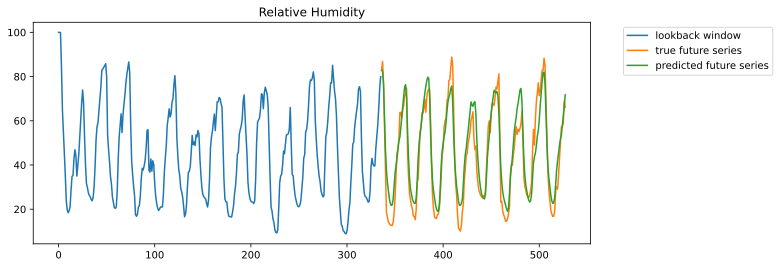

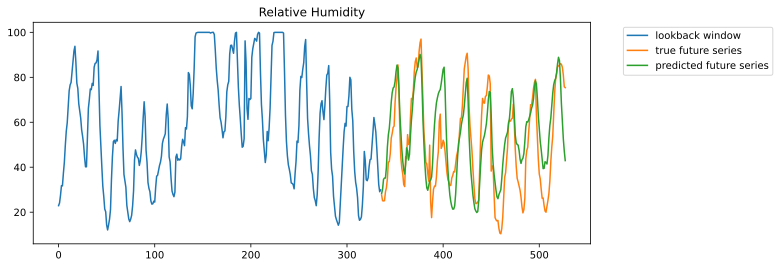

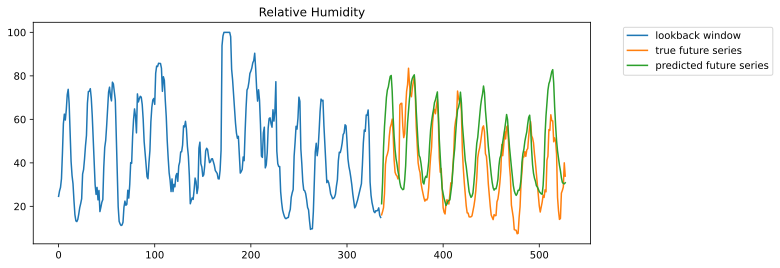

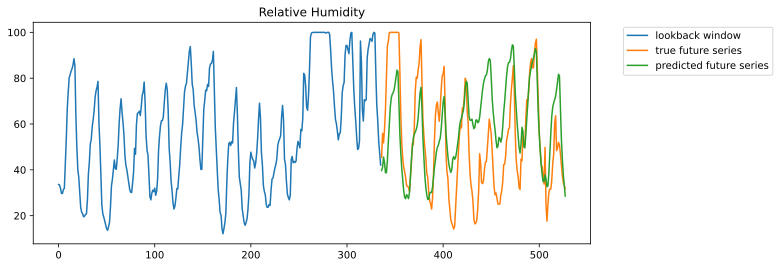

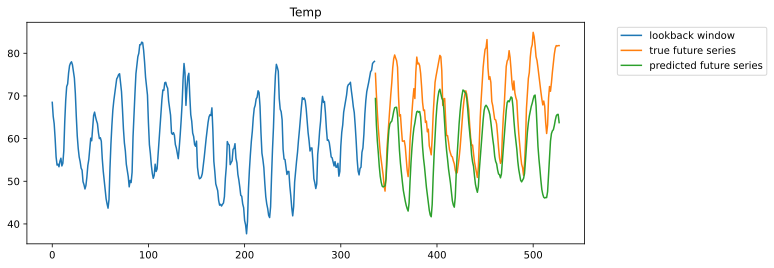

In [53]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner3_2.get_results())),
        weather_val_loader,
        weather_scaler,
        channel_labels=TIME_SERIES_CHANNELS)

### $L=512$, $T=96$

- `PatchTST` loss = 0.317, but 70s per epoch (97 total)
- `LinearPatch` loss = 0.3298. Fast.
- `Linear` loss = 0.3285

In [77]:
traffic_train_loader, traffic_val_loader, _, traffic_scaler = split_time_series_data(
    all_traffic_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=64)

Running experiment: Lin(M=862, L=512, T=96
epoch  1  train loss 0.635  val loss 0.636  (2s)
epoch  2  train loss 0.411  val loss 0.501  (2s)
epoch  3  train loss 0.345  val loss 0.443  (2s)
epoch  4  train loss 0.317  val loss 0.412  (2s)
epoch  5  train loss 0.299  val loss 0.394  (2s)
epoch  6  train loss 0.286  val loss 0.380  (2s)
epoch  7  train loss 0.276  val loss 0.371  (2s)
epoch  8  train loss 0.268  val loss 0.363  (2s)
epoch  9  train loss 0.258  val loss 0.358  (2s)
epoch 10  train loss 0.262  val loss 0.354  (2s)
epoch 11  train loss 0.258  val loss 0.351  (2s)
epoch 12  train loss 0.253  val loss 0.347  (2s)
epoch 13  train loss 0.252  val loss 0.346  (2s)
epoch 14  train loss 0.251  val loss 0.344  (2s)
epoch 15  train loss 0.249  val loss 0.342  (2s)
epoch 16  train loss 0.247  val loss 0.340  (2s)
epoch 17  train loss 0.244  val loss 0.339  (2s)
epoch 18  train loss 0.244  val loss 0.338  (2s)
epoch 19  train loss 0.244  val loss 0.337  (2s)
epoch 20  train loss 0.247

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=862, L=512, T=96",0.3285,98,49248


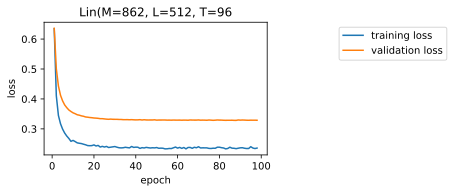

In [78]:
# Match settings in patch_tst
runner3_3 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(traffic_train_loader, traffic_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=all_traffic_data.shape[1],
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

runner_results3_3 = runner3_3.run(verbosity=1)
runner_results3_3

## `LTSFLinear`, $L=512$, $P=720$

- `PatchTST` loss = 0.3905
- `LTSFLinear` loss = 0.3951
- `LinearPatch` loss = 0.3959

In [10]:
all_traffic_data = load_time_series_data("./data/traffic.txt", delimiter=",")
traffic_train_loader, traffic_val_loader, traffic_test_loader, traffic_scaler = split_time_series_data(
    all_traffic_data,
    lookback_size=512,
    prediction_size=720,
    batch_size=64)

Running experiment: Lin(M=862, L=512, T=720
epoch  1  train loss 0.646  val loss 0.670  (15s)
epoch  2  train loss 0.430  val loss 0.551  (15s)
epoch  3  train loss 0.373  val loss 0.500  (15s)
epoch  4  train loss 0.344  val loss 0.472  (15s)
epoch  5  train loss 0.326  val loss 0.455  (15s)
epoch  6  train loss 0.314  val loss 0.443  (15s)
epoch  7  train loss 0.306  val loss 0.435  (15s)
epoch  8  train loss 0.300  val loss 0.428  (15s)
epoch  9  train loss 0.295  val loss 0.423  (15s)
epoch 10  train loss 0.291  val loss 0.419  (15s)
epoch 11  train loss 0.288  val loss 0.415  (15s)
epoch 12  train loss 0.286  val loss 0.413  (15s)
epoch 13  train loss 0.284  val loss 0.410  (15s)
epoch 14  train loss 0.282  val loss 0.408  (15s)
epoch 15  train loss 0.281  val loss 0.407  (15s)
epoch 16  train loss 0.279  val loss 0.405  (15s)
epoch 17  train loss 0.278  val loss 0.404  (15s)
epoch 18  train loss 0.277  val loss 0.403  (15s)
epoch 19  train loss 0.277  val loss 0.402  (15s)
epoch 

,Classifier,Loss (val),Epochs,Param count
0,"Lin(M=862, L=512, T=720",0.3951,82,369360


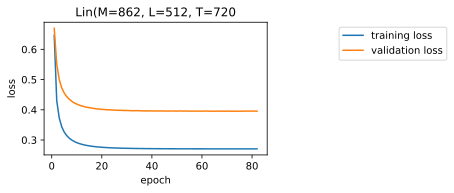

In [8]:
# Match settings in patch_tst
runner4_1 = (
    ExperimentRunner(LTSFLinear)
        .with_epochs(100)
        .with_data(traffic_train_loader, traffic_val_loader)
        .add_experiments(
            LTSFLinearParams(
                num_channels=all_traffic_data.shape[1],
                lookback_size=512,
                prediction_size=720,
            )
        ).with_plots()
)

runner_results4_1 = runner4_1.run(verbosity=1)
runner_results4_1

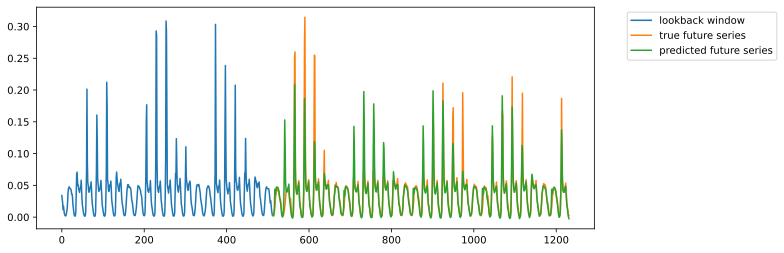

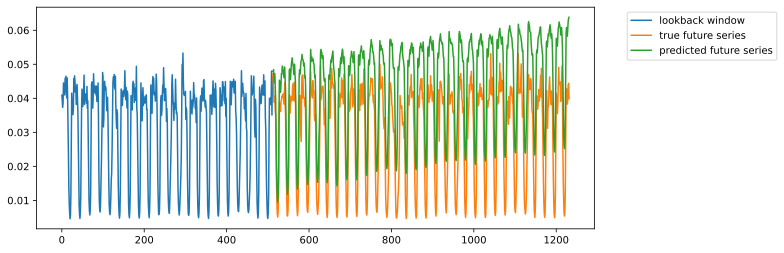

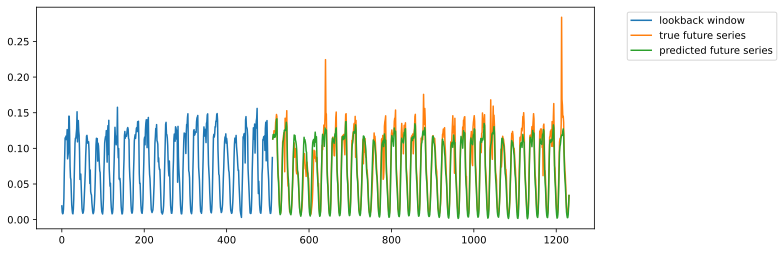

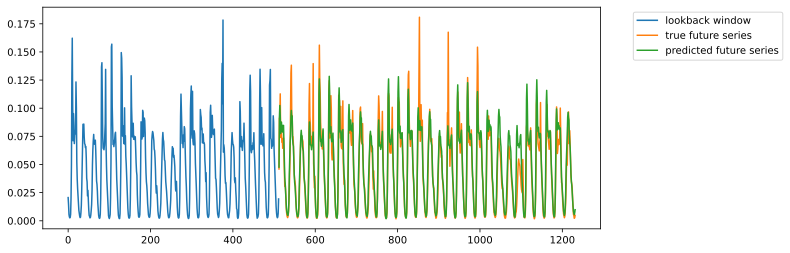

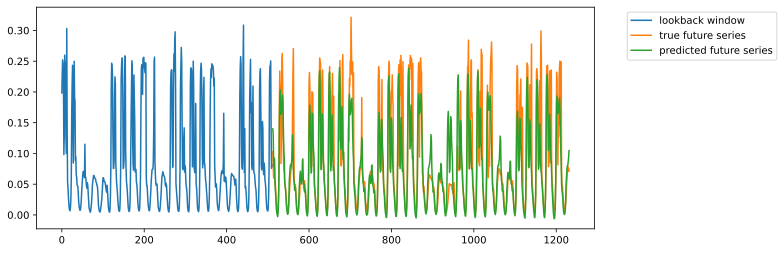

In [9]:
for _ in range(5):
    show_random_prediction(
        list(map(lambda x: x.model, runner4_1.get_results())),
        traffic_val_loader,
        traffic_scaler)

In [11]:
evaluate(runner4_1.get_results()[0].model, traffic_test_loader, nn.MSELoss())

0.4536689790843487

Test loss. Paper's published loss for DLinear was 0.466. Pretty close...